In [9]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import AxesGrid
from salvaged import *
run = 'earth272/'
datadir = '../data/'+run
prefix=''

In [10]:
ptimes=[9.9]
tim=[10.0]
t_eps=0.001
#ThisPatch = Stagger2eMHDPatch
ThisPatch = RamsesMHDPatch
verbose=False
skipped=[]
gamma = 1.4
orbit_radius_au = 1.0
omega = [0.0,0.0,1.0]
pl_pos= [0.0,1.0,0.0]
v_headwind = 0.0   # the headwind the planet feels
v_accretion = 0.0  # accretion rate
density_cgs=3e-12  # external density
times=np.linspace(1,99,99)/10.
    
patches = get_data(time=tim[0],t_eps=t_eps,datadir=datadir, ThisPatch=ThisPatch, gamma=gamma)

159 patches collected for time 10.0


yt : [INFO     ] 2017-03-27 15:28:42,458 Parameters: current_time              = 10.0
yt : [INFO     ] 2017-03-27 15:28:42,458 Parameters: domain_dimensions         = [24 24 24]
yt : [INFO     ] 2017-03-27 15:28:42,459 Parameters: domain_left_edge          = [-15000. -15000. -15000.]
yt : [INFO     ] 2017-03-27 15:28:42,461 Parameters: domain_right_edge         = [ 15000.  15000.  15000.]
yt : [INFO     ] 2017-03-27 15:28:42,462 Parameters: cosmological_simulation   = 0.0
yt : [INFO     ] 2017-03-27 15:28:43,050 xlim = -15000.000000 15000.000000
yt : [INFO     ] 2017-03-27 15:28:43,051 ylim = -15000.000000 15000.000000
yt : [INFO     ] 2017-03-27 15:28:43,053 xlim = -15000.000000 15000.000000
yt : [INFO     ] 2017-03-27 15:28:43,054 ylim = -15000.000000 15000.000000
yt : [INFO     ] 2017-03-27 15:28:43,056 Making a fixed resolution buffer of (('stream', 'e')) 800 by 800



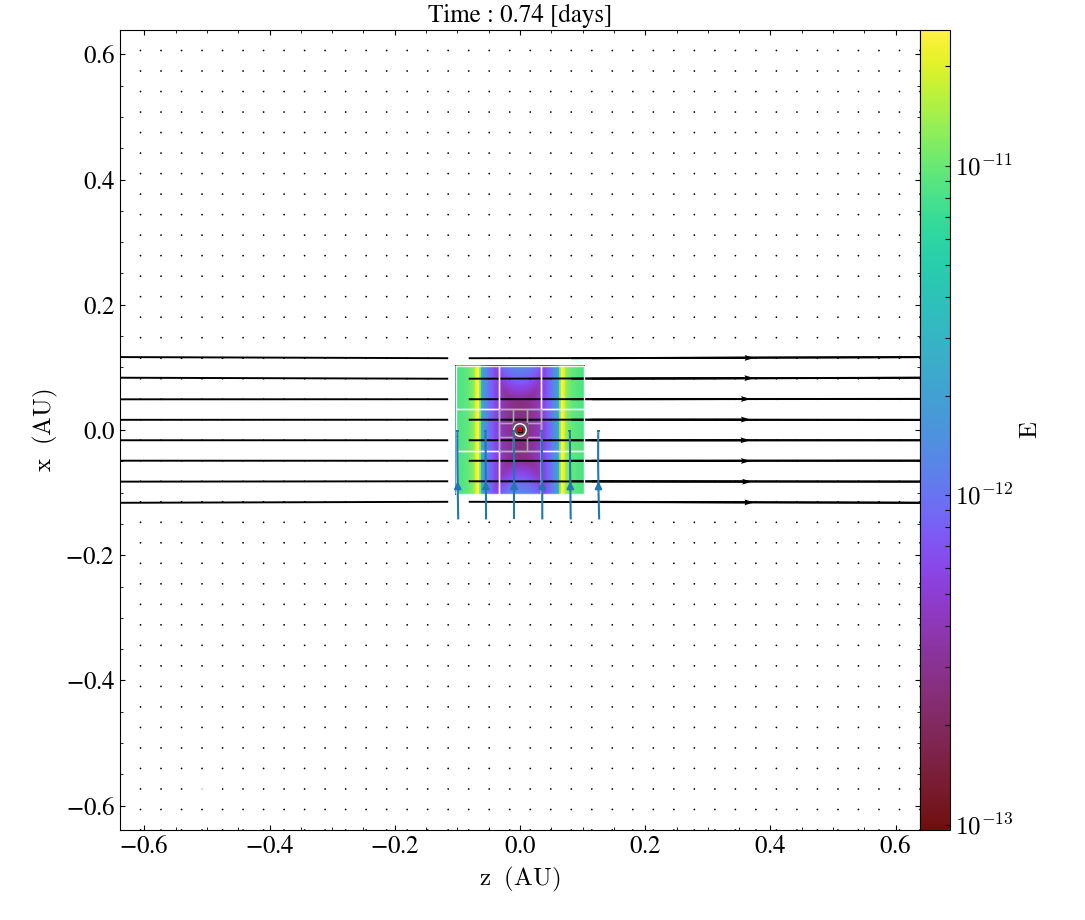

In [14]:
dic=make_yt_dict(patches)
n=patches[0].n
sz=15000
pl_rad=27.
pl_mass=1.0
csound=1.0
restart_time = 0.0
time = patches[0].time+restart_time
bond_rad = pl_mass*sc.scaling().g/csound**2
hill_rad = 235
ds = load_yt(dic,n,sz, time=time)
frc_time = 10.
frc_force = 0.
f_sc = 1-np.exp(-(tim[0]/frc_time)**2)*frc_force
#fig = plt.figure()

slc=yt.SlicePlot(ds=ds,axis="y",fields=["e"],center=[0,0,0])
slc.annotate_velocity(factor=20, normalize=False)
slc.annotate_streamlines('velocity_x', 'velocity_y')
slc.time_unit=sc.scaling().t
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=1, circle_args={'color':'magenta'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=pl_rad, circle_args={'color':'black'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=bond_rad, circle_args={'color':'red'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=hill_rad, circle_args={'color':'white'})
slc.current_time=patches[0].time*sc.scaling().t/3600./24.
slc.annotate_title("Time : %.2f [days]" % ((patches[0].time+restart_time)*sc.scaling().t/3600./24.))#+" Friction parameter: %.4f" %f_sc)
#slc.set_zlim('density',6e-12,3e-11)
#slc.annotate_timestamp()
#slc.zoom(10)
slc.annotate_grids(alpha=0.9)#, draw_ids=True)
slc.annotate_timestamp()
slc.show()

yt : [INFO     ] 2017-03-27 15:28:58,782 Making a fixed resolution buffer of (('stream', 'e')) 800 by 800



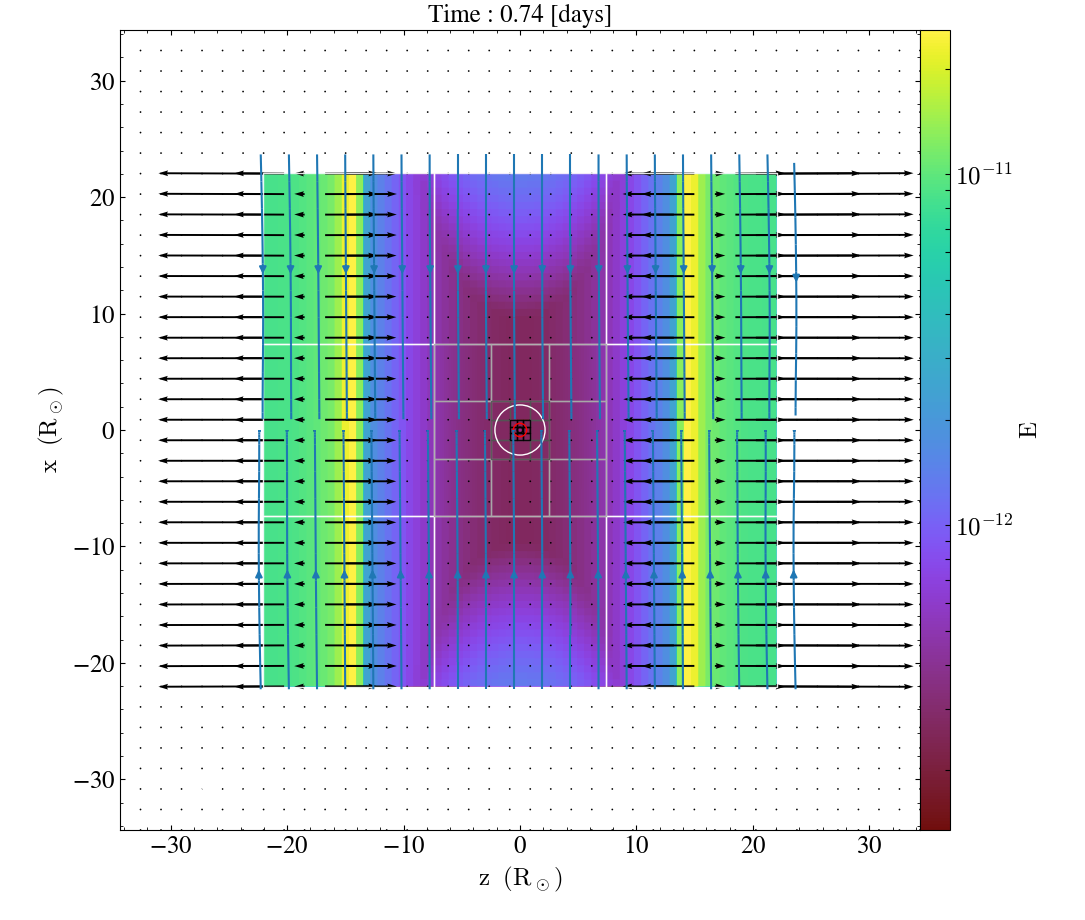

In [16]:
slc.zoom(2)
#slc.set_zlim('temperature',102,1010)
#slc.set_zlim('density',1e-11,1e-10)
#slc.annotate_grids()
slc.show()

In [553]:
slc.save('temperature_1.0')

yt : [INFO     ] 2017-03-26 23:15:27,581 Saving plot temperature_1.0_Slice_y_temperature.png


['temperature_1.0_Slice_y_temperature.png']

In [45]:
slc.close()

AttributeError: 'AxisAlignedSlicePlot' object has no attribute 'close'

In [163]:
my_ray = ds.ortho_ray(0,(0,0))
ray_sort = np.argsort(my_ray["t"])
density = my_ray["density"][ray_sort]

YTFieldNotFound: Could not find field '('all', 't')' in AMRGridData.

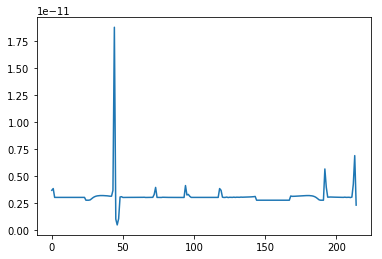

In [165]:
plt.plot(my_ray["density"])
plt.show()

In [203]:
np.exp(-1.)

0.36787944117144233

In [6]:
sc.scaling().temp

242.2828999782719

In [16]:
ee=ds.all_data()

In [120]:
patches[0].velx.max()

3.2248369308263136e-08

In [12]:
gn =patches[0].gn; ng = patches[0].nghost

In [13]:
u=[a-b for a,b in zip(gn,ng)]

In [28]:
patches[8].id

15